<a href="https://colab.research.google.com/github/Nadia080290/redconecta-telecom-ciencia-datos/blob/main/RedConecta_Telecom_Semana8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install pandas numpy scipy joblib matplotlib seaborn openpyxl


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset de RedConecta Telecom
df = pd.read_excel("dataset_set_D_telecomunicaciones.xlsx")

# Mostrar los primeros cinco registros
df.head()


,fecha_registro,region,tipo_servicio,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados,cumplimiento_sla
0,2025-03-01,Centro,Empresas,457.8,21.3,0,27,22.4,144,No cumple
1,2025-03-02,Norte,Internet Hogar,383.4,36.5,13,19,39.4,290,No cumple
2,2025-03-03,Norte,Empresas,457.3,97.4,7,15,1.7,427,Cumple
3,2025-03-04,Norte,Móvil,62.5,119.4,12,30,38.2,116,Cumple
4,2025-03-05,Norte,Empresas,356.1,111.0,9,30,21.5,389,No cumple


In [3]:

# Revisar dimensiones del dataset
print("Dimensiones del dataset:")
print(df.shape)

# Revisar nombres de columnas y tipos de datos
print("\nInformación general:")
df.info()

# Identificar valores nulos por columna
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Obtener estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df.describe())


Dimensiones del dataset:
(200, 10)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fecha_registro          200 non-null    datetime64[ns]
 1   region                  200 non-null    object        
 2   tipo_servicio           200 non-null    object        
 3   trafico_datos_gb        200 non-null    float64       
 4   latencia_ms             200 non-null    float64       
 5   incidencias_reportadas  200 non-null    int64         
 6   tickets_soporte         200 non-null    int64         
 7   tiempo_resolucion_hr    200 non-null    float64       
 8   clientes_afectados      200 non-null    int64         
 9   cumplimiento_sla        200 non-null    object        
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 15.8+ KB

Valores nulos por columna:
fecha_re

,fecha_registro,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados
count,200,200.000000,200.000000,200.000000,200.000000,200.00000,200.00000
mean,2025-06-08 12:00:00,287.229000,64.861500,13.545000,31.390000,25.32950,265.37500
min,2025-03-01 00:00:00,50.500000,11.200000,0.000000,5.000000,1.20000,10.00000
25%,2025-04-19 18:00:00,181.825000,36.875000,6.000000,18.750000,12.70000,146.50000
50%,2025-06-08 12:00:00,289.100000,64.900000,14.000000,31.000000,26.35000,281.50000
75%,2025-07-28 06:00:00,398.750000,91.725000,20.000000,44.000000,37.72500,376.00000
max,2025-09-16 00:00:00,497.900000,119.900000,29.000000,59.000000,47.20000,499.00000
std,NaN,130.551383,32.907065,8.423345,15.521679,13.67296,139.99316


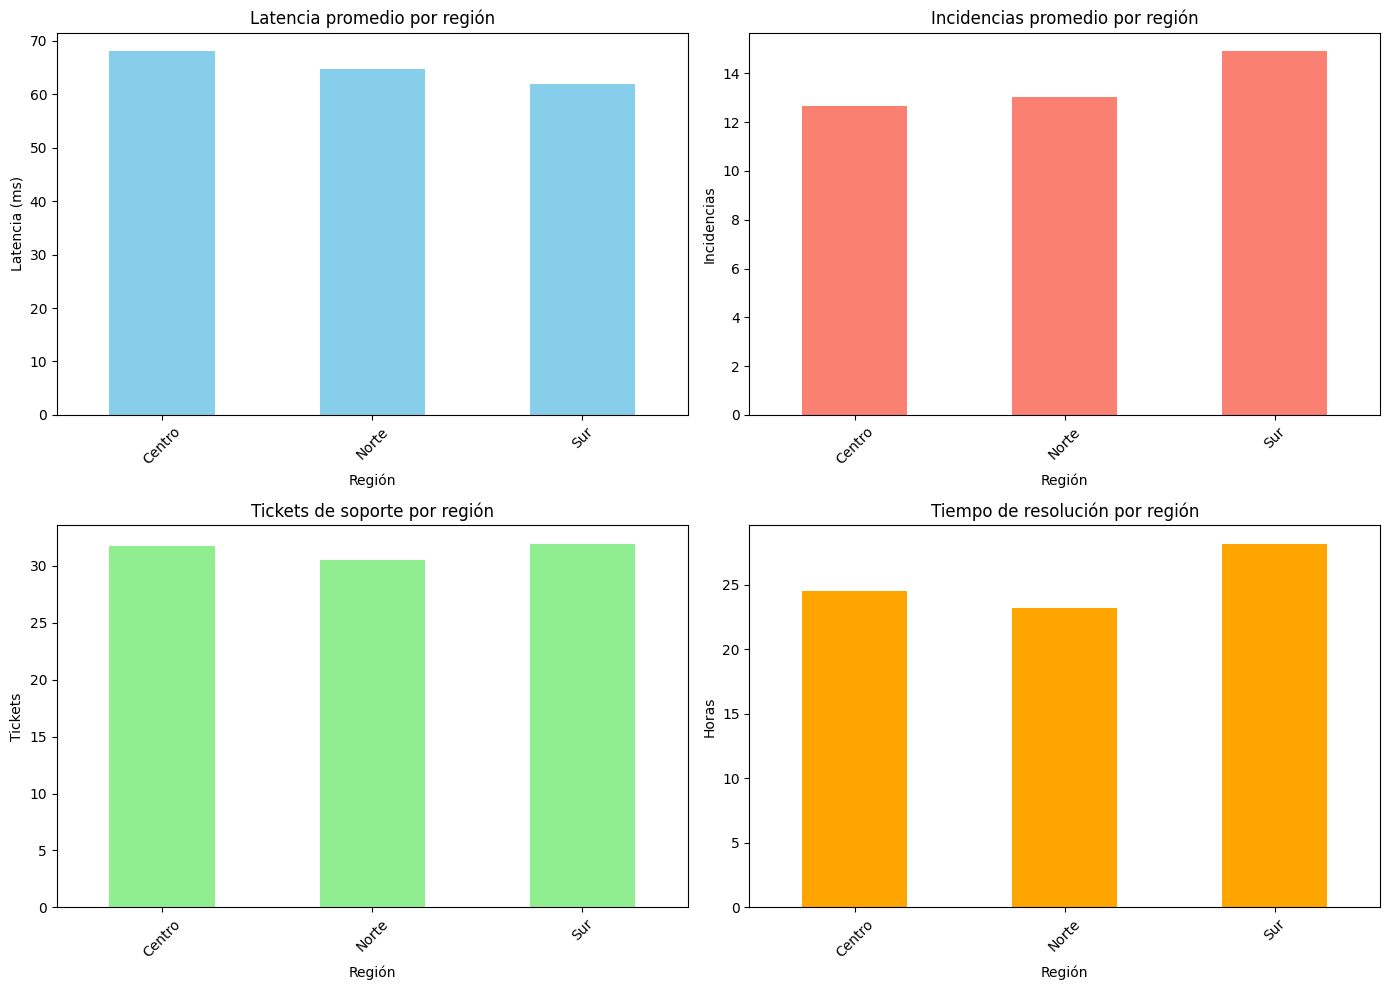

In [4]:

# Agrupar indicadores por región
resumen_region = df.groupby("region")[
    ["latencia_ms", "incidencias_reportadas",
     "tickets_soporte", "tiempo_resolucion_hr"]
].mean()

# Crear dashboard exploratorio
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Latencia promedio por región
resumen_region["latencia_ms"].plot(
    kind="bar", ax=axes[0, 0], color="skyblue"
)
axes[0, 0].set_title("Latencia promedio por región")
axes[0, 0].set_ylabel("Latencia (ms)")

# Gráfico 2: Incidencias promedio por región
resumen_region["incidencias_reportadas"].plot(
    kind="bar", ax=axes[0, 1], color="salmon"
)
axes[0, 1].set_title("Incidencias promedio por región")
axes[0, 1].set_ylabel("Incidencias")

# Gráfico 3: Tickets promedio por región
resumen_region["tickets_soporte"].plot(
    kind="bar", ax=axes[1, 0], color="lightgreen"
)
axes[1, 0].set_title("Tickets de soporte por región")
axes[1, 0].set_ylabel("Tickets")

# Gráfico 4: Tiempo promedio de resolución
resumen_region["tiempo_resolucion_hr"].plot(
    kind="bar", ax=axes[1, 1], color="orange"
)
axes[1, 1].set_title("Tiempo de resolución por región")
axes[1, 1].set_ylabel("Horas")

# Ajustar etiquetas
for ax in axes.flat:
    ax.set_xlabel("Región")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

# Guardar dashboard como imagen
plt.savefig(
    "dashboard_redconecta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Valores registrados en cumplimiento SLA:
cumplimiento_sla
No cumple    104
Cumple        96
Name: count, dtype: int64

Cumplimiento SLA por región:


cumplimiento_sla,Cumple,No cumple
region,,
Centro,30,38
Norte,29,36
Sur,37,30


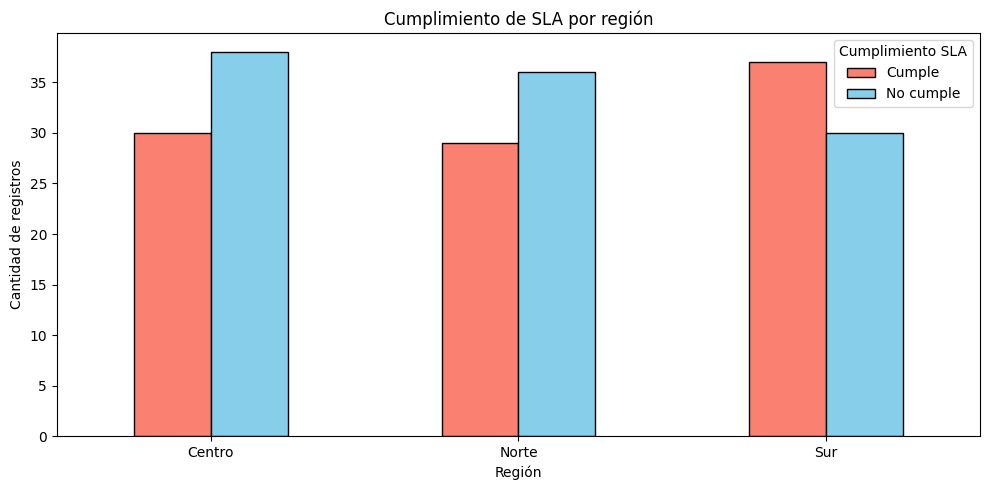

In [5]:

# Revisar los valores del cumplimiento SLA
print("Valores registrados en cumplimiento SLA:")
print(df["cumplimiento_sla"].value_counts(dropna=False))

# Comparar cumplimiento SLA por región
tabla_sla = pd.crosstab(
    df["region"],
    df["cumplimiento_sla"]
)

print("\nCumplimiento SLA por región:")
display(tabla_sla)

# Crear gráfico comparativo
ax = tabla_sla.plot(
    kind="bar",
    figsize=(10, 5),
    color=["salmon", "skyblue", "lightgreen"],
    edgecolor="black"
)

plt.title("Cumplimiento de SLA por región")
plt.xlabel("Región")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.legend(title="Cumplimiento SLA")
plt.tight_layout()

# Guardar gráfico
plt.savefig(
    "cumplimiento_sla_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:

# Reporte para el área de Soporte Técnico
reporte_soporte = df[[
    "fecha_registro",
    "region",
    "tipo_servicio",
    "incidencias_reportadas",
    "tickets_soporte",
    "tiempo_resolucion_hr"
]]

reporte_soporte.to_excel(
    "reporte_soporte_tecnico.xlsx",
    index=False
)

# Reporte para Experiencia de Clientes
reporte_clientes = df[[
    "fecha_registro",
    "tipo_servicio",
    "clientes_afectados",
    "latencia_ms",
    "cumplimiento_sla"
]]

reporte_clientes.to_excel(
    "reporte_experiencia_clientes.xlsx",
    index=False
)

print("Reportes generados correctamente:")
print("1. reporte_soporte_tecnico.xlsx")
print("2. reporte_experiencia_clientes.xlsx")


Reportes generados correctamente:
1. reporte_soporte_tecnico.xlsx
2. reporte_experiencia_clientes.xlsx
